# 03 · Model and evaluation — can AI rank risky transfers better than simple rules?

**Question.** Using only information available **before** a transfer, can a model rank deals by flop risk better than
the rules a scout would apply anyway ("he is too young", "he did not play much last season"), and is the extra
complexity worth it?

### Rules of the game (decided before looking at any test result)

| Item | Choice |
|---|---|
| Split | **by time**: train = transfers up to 2019, validation = 2020-2021, test = 2022-2024. The test set is used **once**, after every choice is fixed |
| Baselines | (0) the average flop rate, (1) four single rules (age, last-season playing time, step up in tier, goalkeeper), (2) **logistic regression** — what an analyst builds in an afternoon |
| Model | **gradient-boosted trees** (`HistGradientBoostingClassifier`): handles missing values natively and can learn interactions such as age × tier change |
| Tuning | hyper-parameters chosen on the validation years only |
| Calibration | probabilities are re-calibrated on the validation years (see section 7) |
| Metrics | ROC-AUC with bootstrap confidence intervals, PR-AUC, Brier score, log-loss, top-decile lift, calibration curve, results **per position / tier / age group** |
| Checks | shuffled-label test, random-vs-time split, alternative label definitions, permutation importance |

*A simple, well-validated result beats a complicated one: if logistic regression is nearly as good as the boosted
trees, we say so.*

## 1 · Setup, data and time split

In [1]:
import os, json, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss, roc_curve

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)

ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
DATA = f"{ROOT}/data/processed/transfers_model.csv.gz"
FIG_DIR, TAB_DIR, MODEL_DIR = f"{ROOT}/reports/figures", f"{ROOT}/reports/tables", f"{ROOT}/models"
for p in (FIG_DIR, TAB_DIR, MODEL_DIR): os.makedirs(p, exist_ok=True)
assert os.path.exists(DATA), "Run notebook 01 first - it creates data/processed/transfers_model.csv.gz"

# --- chart style (same as notebook 02): one accent colour, grey for context, thin marks, solid hairline grid
SURFACE, INK, INK2, GRID, GRAY = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1", "#b9b8b2"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.axisbelow": True, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 1.5, "figure.dpi": 110,
})
def save(fig, name): fig.savefig(f"{FIG_DIR}/{name}.png", dpi=160, bbox_inches="tight")

d = pd.read_csv(DATA)
cols = pd.read_csv(f"{ROOT}/data/processed/columns.csv")
FEATURES = [c for c in cols.loc[cols["role"] == "feature", "column"] if c != "role"]   # "role" (sub-position) is redundant with position
POS_LEVELS, FOOT_LEVELS = ["Attack", "Defender", "Goalkeeper", "Midfield"], ["both", "left", "right"]

def make_X(df):
    """Model matrix: numeric features as they are (NaN allowed), position and foot one-hot encoded with fixed levels."""
    X = df[[f for f in FEATURES if f not in ("main_position", "foot")]].copy()
    for lv in POS_LEVELS: X["pos_" + lv] = (df["main_position"] == lv).astype(float)
    for lv in FOOT_LEVELS: X["foot_" + lv] = (df["foot"] == lv).astype(float)      # unknown foot -> all zeros
    return X

X, y = make_X(d), d["y_flop"]
train, val, test = d["season_y"] <= 2019, d["season_y"].between(2020, 2021), d["season_y"] >= 2022
split = pd.DataFrame({"transfers": [train.sum(), val.sum(), test.sum()],
                      "flop rate": [y[train].mean(), y[val].mean(), y[test].mean()]},
                     index=["train (2012-2019)", "validation (2020-2021)", "test (2022-2024)"])
print(f"{len(FEATURES)} input features -> {X.shape[1]} model columns")
split.round(3)

37 input features -> 42 model columns


,transfers,flop rate
train (2012-2019),24109,0.204
validation (2020-2021),5601,0.160
test (2022-2024),11991,0.160


**Note the drift.** The flop rate was higher in the training years than later. The model will therefore tend to
**over-predict** in the test years even if it ranks well. Ranking quality (AUC) and probability quality (calibration)
are different things, and we check both.

## 2 · Fit the baselines and the model

Everything in this section uses only the **training** years for fitting and the **validation** years for choices.

- **Logistic regression** (analyst baseline): missing values replaced by the median plus a "was missing" flag,
  features standardised, strength of regularisation `C` chosen on validation.
- **Gradient-boosted trees**: a small grid over depth, learning rate, number of trees and leaf size; the best setting is the one with the lowest
  **validation log-loss** (it rewards good probabilities, not only good ranking).

In [2]:
def make_lr(C):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         LogisticRegression(C=C, max_iter=3000))

def make_hgb(**kw):
    return HistGradientBoostingClassifier(l2_regularization=1.0, early_stopping=False, random_state=0, **kw)

# --- logistic regression: choose C on validation
lr_rows = []
for C in [0.01, 0.05, 0.2, 1.0]:
    m = make_lr(C).fit(X[train], y[train]); p = m.predict_proba(X[val])[:, 1]
    lr_rows.append({"C": C, "val AUC": roc_auc_score(y[val], p), "val log-loss": log_loss(y[val], p)})
lr_grid = pd.DataFrame(lr_rows).sort_values("val log-loss")
BEST_C = float(lr_grid.iloc[0]["C"])
print("logistic regression grid (validation):"); display(lr_grid.round(4))

# --- gradient boosting: small grid on validation
grid = list(itertools.product([3, 5], [0.03, 0.06], [150, 300], [50, 200]))
rows = []
for md_, lrate, n_it, leaf in grid:
    m = make_hgb(max_depth=md_, learning_rate=lrate, max_iter=n_it, min_samples_leaf=leaf).fit(X[train], y[train])
    p = m.predict_proba(X[val])[:, 1]
    rows.append({"max_depth": md_, "learning_rate": lrate, "max_iter": n_it, "min_samples_leaf": leaf,
                 "val AUC": roc_auc_score(y[val], p), "val log-loss": log_loss(y[val], p)})
hgb_grid = pd.DataFrame(rows).sort_values("val log-loss").reset_index(drop=True)
BEST = {k: (int(v) if k in ("max_depth", "max_iter", "min_samples_leaf") else float(v))
        for k, v in hgb_grid.iloc[0][["max_depth", "learning_rate", "max_iter", "min_samples_leaf"]].items()}
print(f"gradient boosting: {len(grid)} settings tried; best on validation: {BEST}")
hgb_grid.head(5).round(4)

logistic regression grid (validation):


,C,val AUC,val log-loss
0,0.01,0.7167,0.4085
3,1.00,0.7186,0.4089
2,0.20,0.7183,0.4090
1,0.05,0.7177,0.4090


gradient boosting: 16 settings tried; best on validation: {'max_depth': 5, 'learning_rate': 0.03, 'max_iter': 150, 'min_samples_leaf': 50}


,max_depth,learning_rate,max_iter,min_samples_leaf,val AUC,val log-loss
0,5,0.03,150,50,0.7240,0.4024
1,5,0.03,300,50,0.7241,0.4028
2,5,0.06,150,50,0.7234,0.4029
3,3,0.06,150,50,0.7220,0.4029
4,3,0.03,300,50,0.7224,0.4031


In [3]:
lr_model  = make_lr(BEST_C).fit(X[train], y[train])
hgb_model = make_hgb(**BEST).fit(X[train], y[train])

# --- recalibration (Platt scaling) fitted on the VALIDATION years, which are more recent than the training years
def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
p_val_raw = hgb_model.predict_proba(X[val])[:, 1]
platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p_val_raw).reshape(-1, 1), y[val])
def calibrate(p): return platt.predict_proba(logit(p).reshape(-1, 1))[:, 1]
p_val_lr = lr_model.predict_proba(X[val])[:, 1]                       # same treatment for the logistic baseline
platt_lr = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p_val_lr).reshape(-1, 1), y[val])

# --- predictions on the test years (the only time they are touched)
yt = y[test].values
Xt = X[test]
scores = {                                         # risk scores: higher = riskier
    "age rule (younger = riskier)":      -d.loc[test, "age"].values,
    "playing-time rule":                 -d.loc[test, "prev1_share"].fillna(d["prev1_share"].median()).values,
    "tier-change rule (step up)":         d.loc[test, "tier_change"].fillna(0).values,
    "goalkeeper rule":                    (d.loc[test, "main_position"] == "Goalkeeper").astype(float).values,
    "logistic regression":                lr_model.predict_proba(Xt)[:, 1],
    "gradient boosting":                  hgb_model.predict_proba(Xt)[:, 1],
}
p_hgb_cal = calibrate(scores["gradient boosting"])
p_lr_cal = platt_lr.predict_proba(logit(scores["logistic regression"]).reshape(-1, 1))[:, 1]
print("platt slope/intercept:", platt.coef_.ravel().round(3), platt.intercept_.round(3))
print("mean predicted risk on test: raw", scores["gradient boosting"].mean().round(3), "| calibrated", p_hgb_cal.mean().round(3),
      "| observed", yt.mean().round(3))

platt slope/intercept: [1.136] [-0.284]
mean predicted risk on test: raw 0.218 | calibrated 0.159 | observed 0.16


## 3 · Headline result on the test years

- **ROC-AUC:** chance a randomly chosen flop is ranked riskier than a randomly chosen non-flop (0.5 = coin flip).
  95 % intervals come from 1,000 bootstrap resamples of the test transfers.
- **PR-AUC:** like AUC but focused on finding flops; compare it with the flop rate (the score of a random ranking).
- **Brier score / log-loss:** quality of the probabilities themselves (lower is better; only for models that output
  probabilities). Both models are recalibrated on the validation years in the same way, so this comparison is fair.
- **Lift @ 10 %:** if the club flags the 10 % riskiest deals, how many times more flops are among them than in an
  average group of deals.

In [4]:
def top_k(score, yv, frac):
    k = int(round(frac * len(score)))
    idx = np.argsort(-score, kind="stable")[:k]
    return yv[idx].mean()

RNG = np.random.default_rng(0)
B = 1000
boot_idx = RNG.integers(0, len(yt), size=(B, len(yt)))
def boot_auc(score):
    return np.array([roc_auc_score(yt[i], score[i]) for i in boot_idx])

all_scores = {**scores, "logistic regression": p_lr_cal, "gradient boosting (calibrated)": p_hgb_cal}   # same AUC, honest probabilities
boots = {k: boot_auc(v) for k, v in all_scores.items() if k != "gradient boosting"}   # raw and calibrated GB have identical AUC
boots["gradient boosting"] = boots["gradient boosting (calibrated)"]

rows = []
base = yt.mean()
rows.append({"model": "average flop rate (no model)", "AUC": 0.5, "AUC 95% CI": "-", "PR-AUC": base,
             "Brier": brier_score_loss(yt, np.full(len(yt), y[train].mean())), "log-loss": log_loss(yt, np.full(len(yt), y[train].mean())),
             "precision @ top 10%": base, "lift @ 10%": 1.0})
for name, s in all_scores.items():
    if name == "gradient boosting": continue
    is_prob = name in ("logistic regression", "gradient boosting (calibrated)")
    lo, hi = np.percentile(boots[name], [2.5, 97.5])
    prec10 = top_k(s, yt, 0.10)
    rows.append({"model": name, "AUC": roc_auc_score(yt, s), "AUC 95% CI": f"{lo:.3f}-{hi:.3f}", "PR-AUC": average_precision_score(yt, s),
                 "Brier": brier_score_loss(yt, s) if is_prob else np.nan, "log-loss": log_loss(yt, s) if is_prob else np.nan,
                 "precision @ top 10%": prec10, "lift @ 10%": prec10 / base})
results = pd.DataFrame(rows).set_index("model")
results.round(3).to_csv(f"{TAB_DIR}/03_test_results.csv")
results.round(3)

,AUC,AUC 95% CI,PR-AUC,Brier,log-loss,precision @ top 10%,lift @ 10%
model,,,,,,,
average flop rate (no model),0.500,-,0.160,0.136,0.446,0.160,1.000
age rule (younger = riskier),0.589,0.574-0.604,0.262,NaN,NaN,0.340,2.124
playing-time rule,0.559,0.546-0.573,0.201,NaN,NaN,0.239,1.489
tier-change rule (step up),0.540,0.529-0.552,0.181,NaN,NaN,0.215,1.343
goalkeeper rule,0.563,0.555-0.572,0.202,NaN,NaN,0.340,2.124
logistic regression,0.687,0.674-0.701,0.354,0.122,0.405,0.436,2.723
gradient boosting (calibrated),0.694,0.681-0.707,0.360,0.122,0.401,0.448,2.796


In [5]:
# Is the gain over the baselines real? Paired bootstrap of the AUC difference (same resamples for both models)
def diff_ci(a, b):
    dlt = boots[a] - boots[b]
    return roc_auc_score(yt, all_scores[a]) - roc_auc_score(yt, all_scores[b]), *np.percentile(dlt, [2.5, 97.5])

pairs = [("gradient boosting (calibrated)", "age rule (younger = riskier)"),
         ("logistic regression", "age rule (younger = riskier)"),
         ("gradient boosting (calibrated)", "logistic regression")]
pd.DataFrame([{"comparison": f"{a}  minus  {b}", "AUC difference": v, "95% CI low": lo, "95% CI high": hi}
              for (a, b) in pairs for v, lo, hi in [diff_ci(a, b)]]).round(3)

,comparison,AUC difference,95% CI low,95% CI high
0,gradient boosting (calibrated) minus age rul...,0.105,0.090,0.122
1,logistic regression minus age rule (younger ...,0.098,0.084,0.113
2,gradient boosting (calibrated) minus logisti...,0.007,0.000,0.014


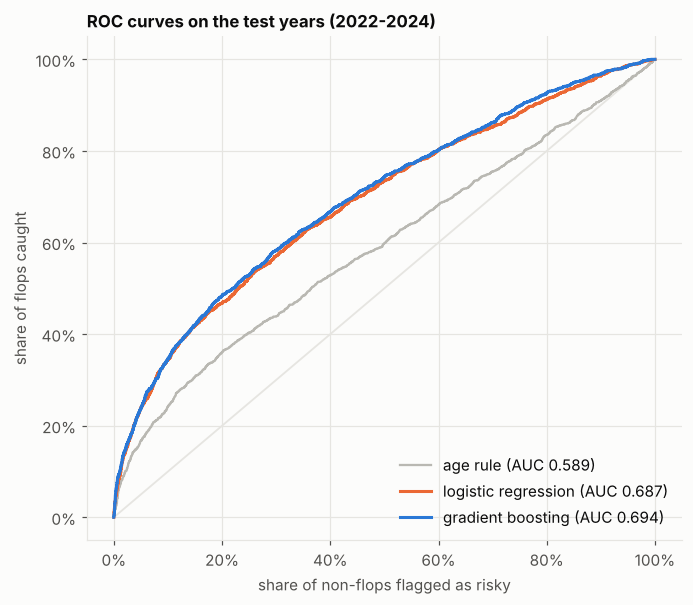

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 5.6))
for name, col, lw, lab in [("age rule (younger = riskier)", GRAY, 1.5, "age rule"),
                           ("logistic regression", ORANGE, 2, "logistic regression"),
                           ("gradient boosting", BLUE, 2, "gradient boosting")]:
    fpr, tpr, _ = roc_curve(yt, scores[name])
    ax.plot(fpr, tpr, color=col, lw=lw, label=f"{lab} (AUC {roc_auc_score(yt, scores[name]):.3f})")
ax.plot([0, 1], [0, 1], color=GRID, lw=1.2, zorder=1)
ax.set_xlabel("share of non-flops flagged as risky"); ax.set_ylabel("share of flops caught")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title("ROC curves on the test years (2022-2024)"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); save(fig, "03_roc_curves"); plt.show()

**Reading the headline.**

- **Both models clearly beat every single rule.** The best rule (age) reaches AUC 0.59; logistic regression 0.69 and
  gradient boosting 0.69 (+0.10, interval well above 0). Flagging the riskiest 10 % of deals gives a flop rate of about
  45 % against 16 % overall (lift 2.8, versus 2.1 for the age rule).
- **Gradient boosting vs logistic regression: a small edge.** +0.007 AUC, with an interval that touches 0, and practically
  the same probability quality once both are recalibrated (log-loss 0.401 vs 0.405, Brier 0.122 for both). We keep gradient boosting because it is never worse, but an analyst's logistic regression
  gets almost all of the value. This is the honest answer to "is the complexity worth it?": mostly **no** for ranking.
- **A modest ceiling.** AUC 0.69 means useful, not decisive: many flops are unpredictable from pre-transfer data
  (injury after arrival, change of coach, form). We present this as a *screening* tool, not a verdict on a player.

The next sections test whether these numbers can be trusted.

## 4 · Can we trust it? Sanity checks

### 4.1 Shuffled labels
If we **randomly shuffle** which transfer was a flop and retrain the same model, it can learn nothing real. Its test
AUC must be ≈ 0.5. If it were clearly higher, the pipeline would be leaking information. We repeat with several random
shuffles to see the spread.

In [7]:
rows = []
for seed in range(8):
    y_shuf = y[train].sample(frac=1, random_state=seed).values
    m = make_hgb(**BEST).fit(X[train], y_shuf)
    rows.append(roc_auc_score(yt, m.predict_proba(Xt)[:, 1]))
shuf = np.array(rows)
print(f"shuffled-label test AUC over 8 shuffles: mean {shuf.mean():.3f}, sd {shuf.std(ddof=1):.3f}, range {shuf.min():.3f}-{shuf.max():.3f}")

shuffled-label test AUC over 8 shuffles: mean 0.504, sd 0.026, range 0.463-0.535


### 4.2 Time-based vs random split
A **random** split lets the model train on transfers from the same seasons as the ones it is tested on. We compare it
with the honest time-based split to see how much a careless evaluation would inflate the result.

In [8]:
idx = np.random.default_rng(1).random(len(d)) < 0.8
m_rand = make_hgb(**BEST).fit(X[idx], y[idx])
auc_random = roc_auc_score(y[~idx], m_rand.predict_proba(X[~idx])[:, 1])
auc_time = roc_auc_score(yt, scores["gradient boosting"])
pd.DataFrame({"AUC": [auc_random, auc_time]}, index=["random 80/20 split (not allowed for forecasting)", "time split (train <= 2019, test 2022-2024)"]).round(3)

,AUC
random 80/20 split (not allowed for forecasting),0.701
"time split (train <= 2019, test 2022-2024)",0.694


**Reading the checks.** Shuffled labels give AUC ≈ 0.50 (range 0.46-0.54), so the pipeline does not create signal out
of nothing. The random split scores only slightly higher than the time split (0.70 vs 0.69): the inflation from careless
evaluation is small here, which also tells us the relationships are fairly stable over time. We still report the time
split because it is the one that matches how the tool would really be used.

## 5 · Where does it work? Position, tier and age

An overall AUC can hide a lot: goalkeepers are a different population (their flop rate is 40 % against 14 % for outfield players in the test years), and
the 'goalkeeper' flag alone already separates them from the rest. We therefore compute the AUC **inside** each group, so
that a model cannot score well only by telling groups apart.

In [9]:
t = d[test].reset_index(drop=True)
groups = {
    "outfield players":         t["main_position"] != "Goalkeeper",
    "goalkeepers":              t["main_position"] == "Goalkeeper",
    "destination tier 1":       t["dest_level"] == 1,
    "destination tier 2":       t["dest_level"] == 2,
    "destination tier 3+":      t["dest_level"] >= 3,
    "age ≤ 22":                 np.floor(t["age"]) <= 22,
    "age 23-29":                np.floor(t["age"]).between(23, 29),
    "age 30+":                  np.floor(t["age"]) >= 30,
}
rows = []
for g, m in groups.items():
    m = m.values
    row = {"group": g, "n": int(m.sum()), "flop rate": yt[m].mean()}
    for lab, key in [("age rule", "age rule (younger = riskier)"), ("logistic regression", "logistic regression"), ("gradient boosting", "gradient boosting")]:
        row[lab] = roc_auc_score(yt[m], scores[key][m])
    rows.append(row)
sub = pd.DataFrame(rows)
sub.round(3).to_csv(f"{TAB_DIR}/03_subgroup_auc.csv", index=False)
sub.round(3)

,group,n,flop rate,age rule,logistic regression,gradient boosting
0,outfield players,11130,0.142,0.612,0.652,0.662
1,goalkeepers,861,0.396,0.554,0.709,0.711
2,destination tier 1,5022,0.190,0.600,0.718,0.718
3,destination tier 2,3146,0.154,0.589,0.674,0.697
4,destination tier 3+,1824,0.112,0.589,0.692,0.681
5,age ≤ 22,2450,0.264,0.640,0.686,0.697
6,age 23-29,6963,0.131,0.518,0.653,0.652
7,age 30+,2578,0.139,0.488,0.670,0.678


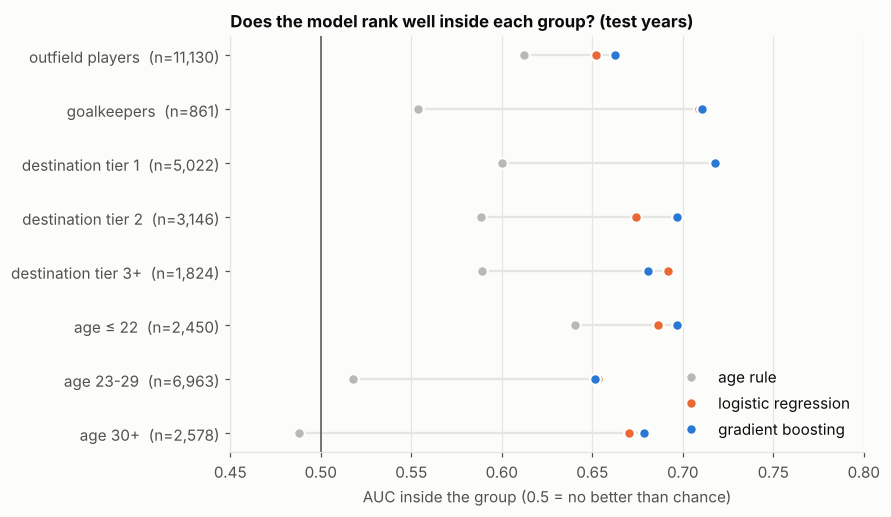

In [10]:
fig, ax = plt.subplots(figsize=(8.2, 4.8))
yy = np.arange(len(sub))[::-1]
ax.hlines(yy, sub[["age rule", "logistic regression", "gradient boosting"]].min(axis=1),
          sub[["age rule", "logistic regression", "gradient boosting"]].max(axis=1), color=GRID, lw=1.5, zorder=1)
for col, c, lab in [("age rule", GRAY, "age rule"), ("logistic regression", ORANGE, "logistic regression"), ("gradient boosting", BLUE, "gradient boosting")]:
    ax.plot(sub[col], yy, "o", color=c, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, label=lab, zorder=3)
ax.axvline(0.5, color=INK2, lw=1, zorder=1)
ax.set_yticks(yy); ax.set_yticklabels([f"{g}  (n={n:,})" for g, n in zip(sub["group"], sub["n"])]); ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC inside the group (0.5 = no better than chance)"); ax.set_xlim(0.45, 0.8)
ax.set_title("Does the model rank well inside each group? (test years)"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); save(fig, "03_subgroup_auc"); plt.show()

**Reading the groups.** The model beats the age rule in every group, with the biggest gains for goalkeepers and
players aged 30+ and the smallest for the youngest players, where "he is young" already says most of what is knowable
(the age rule is, by construction, weak *inside* an age band, so compare the models with each other there). Inside
**outfield players only** the model reaches 0.66 against 0.61 for the age rule: better, but a modest margin, so the
overall AUC is helped by telling goalkeepers apart. Gradient boosting and logistic regression are within about 0.02 of
each other in every group; with groups this small (goalkeepers: 861 transfers) we do not read those differences as real.

## 6 · Are the probabilities honest? Calibration

AUC says nothing about whether "30 % risk" really means 30 flops in 100. A **reliability plot** groups the test
transfers into ten bins by predicted risk and compares the average prediction with what really happened; points on the
diagonal are perfectly calibrated. We show the raw model and the version recalibrated on the validation years.

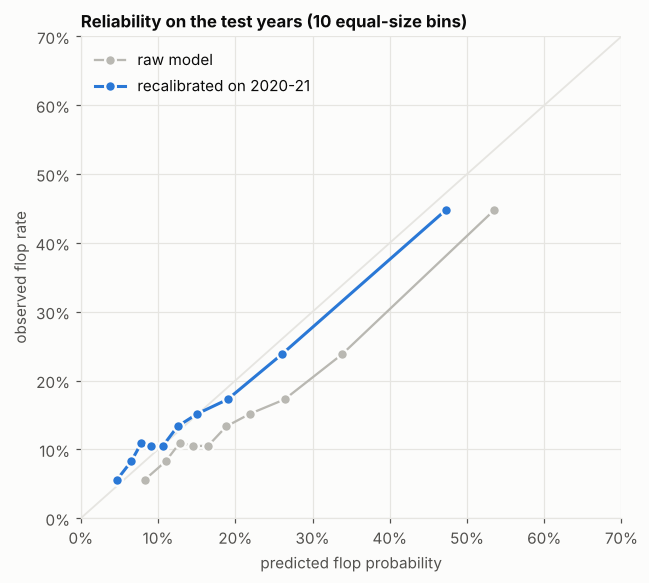

,mean predicted,observed,Brier,log-loss
raw model,0.2176,0.1602,0.1253,0.4117
recalibrated,0.1588,0.1602,0.1216,0.4010


In [11]:
def reliability(p, bins=10):
    b = pd.qcut(p, bins, duplicates="drop")
    g = pd.DataFrame({"p": p, "y": yt}).groupby(b, observed=True).agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size"))
    return g
rel_raw, rel_cal = reliability(scores["gradient boosting"]), reliability(p_hgb_cal)

fig, ax = plt.subplots(figsize=(6, 5.4))
ax.plot([0, 0.7], [0, 0.7], color=GRID, lw=1.2, zorder=1)
ax.plot(rel_raw["pred"], rel_raw["obs"], "-o", color=GRAY, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, label="raw model")
ax.plot(rel_cal["pred"], rel_cal["obs"], "-o", color=BLUE, lw=2, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, label="recalibrated on 2020-21")
ax.set_xlim(0, 0.7); ax.set_ylim(0, 0.7)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("predicted flop probability"); ax.set_ylabel("observed flop rate")
ax.set_title("Reliability on the test years (10 equal-size bins)"); ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); save(fig, "03_calibration"); plt.show()

pd.DataFrame({"mean predicted": [scores["gradient boosting"].mean(), p_hgb_cal.mean()], "observed": [yt.mean()] * 2,
              "Brier": [brier_score_loss(yt, scores["gradient boosting"]), brier_score_loss(yt, p_hgb_cal)],
              "log-loss": [log_loss(yt, scores["gradient boosting"]), log_loss(yt, p_hgb_cal)]},
             index=["raw model", "recalibrated"]).round(4)

## 7 · What is it worth to a club? Decision value

A sporting director cannot read 100 deals one by one but can **flag the riskiest few for a second opinion**. The gains
chart shows how many of all flops end up in the flagged group when we flag the riskiest x % of deals.

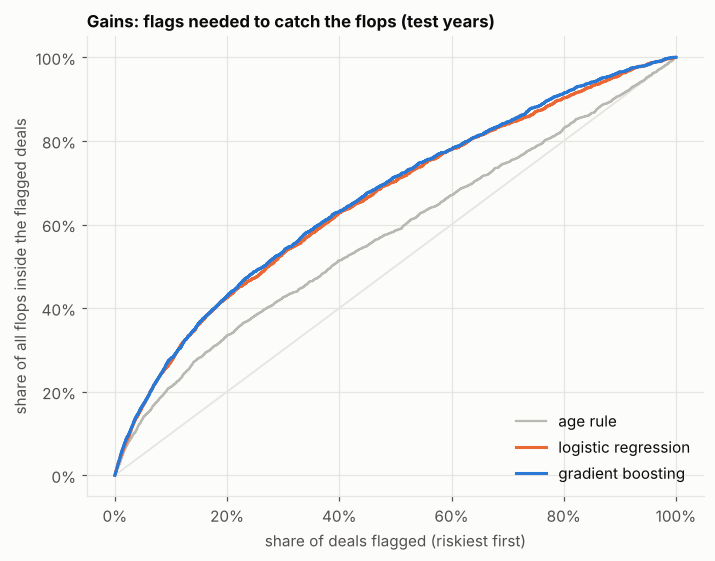

In [12]:
def gains_curve(score):
    order = np.argsort(-score, kind="stable")
    caught = np.cumsum(yt[order]) / yt.sum()
    return np.arange(1, len(yt) + 1) / len(yt), caught

fig, ax = plt.subplots(figsize=(6.6, 5.2))
ax.plot([0, 1], [0, 1], color=GRID, lw=1.2, zorder=1)
for name, col, lw, lab in [("age rule (younger = riskier)", GRAY, 1.5, "age rule"), ("logistic regression", ORANGE, 2, "logistic regression"),
                           ("gradient boosting", BLUE, 2, "gradient boosting")]:
    x_, y_ = gains_curve(scores[name]); ax.plot(x_, y_, color=col, lw=lw, label=lab)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("share of deals flagged (riskiest first)"); ax.set_ylabel("share of all flops inside the flagged deals")
ax.set_title("Gains: flags needed to catch the flops (test years)"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); save(fig, "03_gains_curve"); plt.show()

In [13]:
fee = np.expm1(d.loc[test, "log_fee"].values)                       # transfer fee in euro (0 = free or undisclosed)
order = np.argsort(-p_hgb_cal, kind="stable")
rows = []
for frac in [0.05, 0.10, 0.20, 0.30, 0.40]:
    k = int(round(frac * len(yt))); flag = np.zeros(len(yt), bool); flag[order[:k]] = True
    paid = fee > 0
    rows.append({"flag riskiest": f"{frac:.0%}", "flop rate inside flagged": yt[flag].mean(), "lift": yt[flag].mean() / yt.mean(),
                 "flops caught": yt[flag].sum() / yt.sum(),
                 "fee money flagged": fee[flag].sum() / fee.sum(),
                 "fees paid for flops that were flagged": fee[flag & (yt == 1)].sum() / fee[yt == 1].sum()})
dec = pd.DataFrame(rows).set_index("flag riskiest")
dec.round(3).to_csv(f"{TAB_DIR}/03_decision_value.csv")
print(f"test transfers with a disclosed fee > 0: {(fee > 0).sum():,} | total disclosed fees: EUR {fee.sum()/1e6:,.0f} m "
      f"| fees paid for players who flopped: EUR {fee[yt == 1].sum()/1e6:,.0f} m ({fee[yt == 1].sum()/fee.sum():.1%})")
dec.round(3)

test transfers with a disclosed fee > 0: 3,769 | total disclosed fees: EUR 20,306 m | fees paid for players who flopped: EUR 2,455 m (12.1%)


,flop rate inside flagged,lift,flops caught,fee money flagged,fees paid for flops that were flagged
flag riskiest,,,,,
5%,0.540,3.371,0.169,0.025,0.117
10%,0.448,2.796,0.280,0.055,0.217
20%,0.343,2.142,0.428,0.115,0.333
30%,0.286,1.787,0.536,0.176,0.464
40%,0.253,1.577,0.631,0.231,0.554


**Reading the table.** The trade-off is explicit: flagging more deals catches more flops but also sends more good
signings to a second look. How far to go is a **business** choice (cost of a second opinion vs cost of a flop), not a
statistical one. The two right-hand columns relate the flags to disclosed transfer fees; *fees paid for players who
flopped* is **not** a loss figure: a player who flops can often still be resold, and free or undisclosed fees count as
zero.

The table shows something to keep in mind: the riskiest 10 % of deals hold only about 5 % of the disclosed fee money
and catch about 22 % of the money paid for players who flopped (against 28 % of the flops themselves). The model
mostly finds *cheap* risky deals (young, low-profile signings); expensive flops are harder to anticipate.

## 8 · Do the conclusions depend on how a flop is defined?

Notebook 02 showed the age and step-up signals weaken without the zero-appearance rows (some of those players may play
only for a reserve team). We retrain and test **under each alternative label**, always with time-based splits.

In [14]:
variants = {
    "flop = plays < 25 %  (main definition)":      (d["share_after"] < 0.25, pd.Series(True, index=d.index)),
    "flop = plays < 15 %":                          (d["share_after"] < 0.15, pd.Series(True, index=d.index)),
    "flop = plays < 33 %":                          (d["share_after"] < 0.33, pd.Series(True, index=d.index)),
    "plays < 25 %, zero-appearance rows removed":   (d["share_after"] < 0.25, d["apps_after"] > 0),
}
rows = []
for name, (lab, keep) in variants.items():
    lab = lab.astype(int); tr_m, te_m = train & keep, test & keep
    lr_v  = make_lr(BEST_C).fit(X[tr_m], lab[tr_m]); hgb_v = make_hgb(**BEST).fit(X[tr_m], lab[tr_m])
    rows.append({"label definition": name, "test flop rate": lab[te_m].mean(), "n test": int(te_m.sum()),
                 "age rule": roc_auc_score(lab[te_m], -d.loc[te_m, "age"]),
                 "logistic regression": roc_auc_score(lab[te_m], lr_v.predict_proba(X[te_m])[:, 1]),
                 "gradient boosting": roc_auc_score(lab[te_m], hgb_v.predict_proba(X[te_m])[:, 1])})
robust = pd.DataFrame(rows).set_index("label definition")
robust.round(3).to_csv(f"{TAB_DIR}/03_label_robustness.csv")
robust.round(3)

,test flop rate,n test,age rule,logistic regression,gradient boosting
label definition,,,,,
flop = plays < 25 % (main definition),0.160,11991,0.589,0.687,0.694
flop = plays < 15 %,0.113,11991,0.610,0.712,0.727
flop = plays < 33 %,0.205,11991,0.576,0.671,0.679
"plays < 25 %, zero-appearance rows removed",0.112,11343,0.568,0.669,0.669


## 9 · What drives the predictions?

**Permutation importance:** shuffle one feature in the test data and measure how much the AUC drops; the bigger the
drop, the more the model relies on it. Features that carry similar information (e.g. injury counts and days) share
credit, so read the ranking as a guide, not as exact weights. **Partial dependence** then shows how the predicted
risk changes when one feature varies and the rest stay as they are.

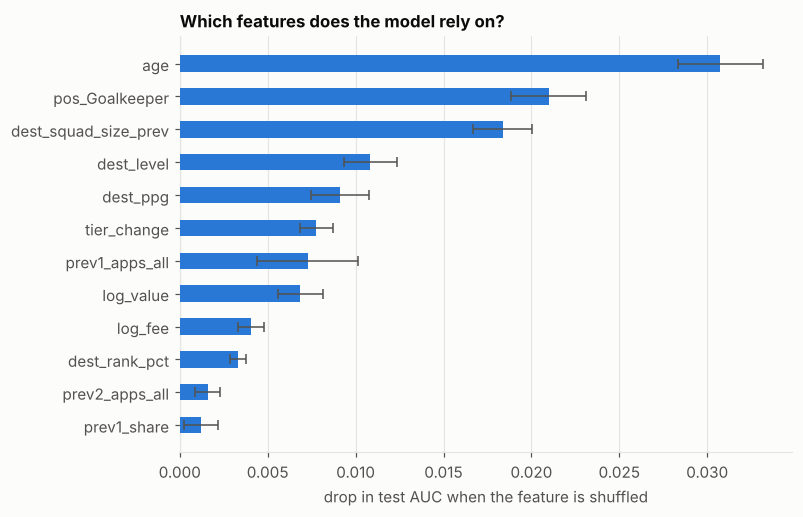

,feature,auc_drop,sd
0,age,0.0308,0.0024
1,pos_Goalkeeper,0.0210,0.0021
2,dest_squad_size_prev,0.0184,0.0017
3,dest_level,0.0108,0.0015
4,dest_ppg,0.0091,0.0016
5,tier_change,0.0078,0.0009
6,prev1_apps_all,0.0073,0.0029
7,log_value,0.0069,0.0013
8,log_fee,0.0040,0.0007
9,dest_rank_pct,0.0033,0.0004


In [15]:
imp = permutation_importance(hgb_model, Xt, yt, scoring="roc_auc", n_repeats=8, random_state=0)
imp = pd.DataFrame({"feature": X.columns, "auc_drop": imp.importances_mean, "sd": imp.importances_std}).sort_values("auc_drop", ascending=False)
imp.round(4).to_csv(f"{TAB_DIR}/03_permutation_importance.csv", index=False)

top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.4, 4.8))
ax.barh(top["feature"], top["auc_drop"], height=0.5, color=BLUE, zorder=3)
ax.errorbar(top["auc_drop"], top["feature"], xerr=top["sd"], fmt="none", ecolor=INK2, elinewidth=1, capsize=3, zorder=4)
ax.grid(axis="y", visible=False); ax.set_xlabel("drop in test AUC when the feature is shuffled")
ax.set_title("Which features does the model rely on?")
plt.tight_layout(); save(fig, "03_permutation_importance"); plt.show()
imp.head(12).round(4).reset_index(drop=True)

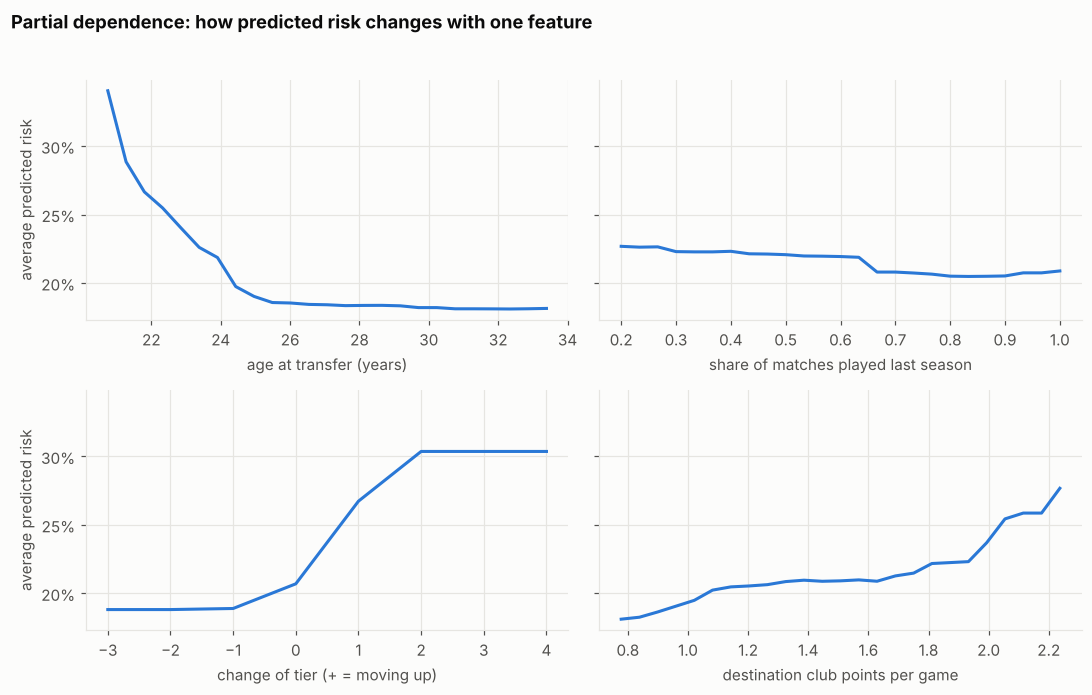

In [16]:
pdp_feats = [("age", "age at transfer (years)"), ("prev1_share", "share of matches played last season"),
             ("tier_change", "change of tier (+ = moving up)"), ("dest_ppg", "destination club points per game")]
Xp = Xt.dropna(subset=[f for f, _ in pdp_feats])
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharey=True)
for ax, (f, lab) in zip(axes.ravel(), pdp_feats):
    r = partial_dependence(hgb_model, Xp, [f], grid_resolution=25, kind="average", method="brute")   # brute force = average predicted probability
    ax.plot(r["grid_values"][0], r["average"][0], color=BLUE, lw=2)
    ax.set_xlabel(lab); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0, 0].set_ylabel("average predicted risk"); axes[1, 0].set_ylabel("average predicted risk")
fig.suptitle("Partial dependence: how predicted risk changes with one feature", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.96)); save(fig, "03_partial_dependence"); plt.show()

The importance ranking and the curves agree with the exploratory analysis: young age, a step up in tier, a strong
destination club and little recent playing time raise the predicted risk, and the model has learnt these effects from
the data rather than from rules we typed in. As always, these are **associations**: the curves describe what the model
learnt about the transfer market, not what would happen if a club changed one input.

## 10 · Look at actual cases

Numbers are easier to defend with examples. The first table lists the deals the model rated riskiest among the
test years, the second the flops it did **not** see coming (lowest predicted risk).

In [17]:
show = t[["player_name", "from_team_name", "to_team_name", "season_y", "age", "main_position", "share_after", "y_flop"]].copy()
show["predicted_risk"] = p_hgb_cal
show["age"] = show["age"].round(1); show["share_after"] = show["share_after"].round(2); show["predicted_risk"] = show["predicted_risk"].round(2)
print("Riskiest predictions:")
display(show.sort_values("predicted_risk", ascending=False).head(10).reset_index(drop=True))
print("Flops the model did not expect (lowest predicted risk among actual flops):")
display(show[show["y_flop"] == 1].sort_values("predicted_risk").head(10).reset_index(drop=True))
print("share of the 100 riskiest predictions that really flopped:", show.sort_values("predicted_risk", ascending=False).head(100)["y_flop"].mean().round(2))

Riskiest predictions:


,player_name,from_team_name,to_team_name,season_y,age,main_position,share_after,y_flop,predicted_risk
0,Martim Marques,Sporting B,FC Lugano,2023,19.4,Defender,0.32,0,0.91
1,Ifeanyi David Nduka,Botev Plovdiv,Krasnodar,2022,18.6,Midfield,0.03,1,0.90
2,Saël Kumbedi,Le Havre AC,Olympique Lyon,2022,17.4,Defender,0.53,0,0.88
3,Simon Eriksson,FC Stockholm,Elfsborg,2024,18.3,Goalkeeper,0.00,1,0.87
4,Bastien Meupiyou,FC Nantes,Wolves,2024,18.4,Defender,0.00,1,0.87
5,Marco Delle Monache,Pescara,Sampdoria,2022,17.5,Attack,0.00,1,0.86
6,Axel Guessand,AS Nancy B,Udinese,2022,17.6,Defender,0.03,1,0.86
7,Dzenan Pejcinovic,FC Augsburg U19,VfL Wolfsburg,2022,17.4,Attack,0.03,1,0.86
8,Jayden Meghoma,Southampton U21,Brentford,2024,18.2,Defender,0.03,1,0.86
9,Buba Sangaré,Levante U19,AS Roma,2024,16.9,Defender,0.00,1,0.86


Flops the model did not expect (lowest predicted risk among actual flops):


,player_name,from_team_name,to_team_name,season_y,age,main_position,share_after,y_flop,predicted_risk
0,Jurriën Timber,Ajax,Arsenal,2023,22.1,Defender,0.05,1,0.03
1,Sandro Tonali,AC Milan,Newcastle,2023,23.2,Midfield,0.22,1,0.03
2,Filippo Nardi,Cremonese,Benevento,2024,26.3,Midfield,0.00,1,0.04
3,Jeredy Hilterman,Almere City,Arm. Bielefeld,2024,26.0,Attack,0.08,1,0.04
4,Andrea Petagna,Napoli,Monza,2023,28.0,Attack,0.00,1,0.04
5,Enzo Le Fée,Stade Rennais,AS Roma,2024,24.4,Midfield,0.16,1,0.04
6,Ferdi Kadıoğlu,Fenerbahce,Brighton,2024,24.9,Defender,0.17,1,0.04
7,Marcão,Galatasaray,Sevilla FC,2022,26.1,Defender,0.13,1,0.04
8,Neymar,Paris SG,Al-Hilal,2023,31.5,Midfield,0.09,1,0.04
9,Roland Ndongo,FC Thun,Neuchâtel Xamax,2024,29.7,Midfield,0.08,1,0.04


share of the 100 riskiest predictions that really flopped: 0.73


**Reading the cases.** The riskiest predictions are almost all teenagers, about half of them coming from another club's youth or
reserve side ("B", "U19", "U21") and moving to a first team: they are young, step up, and join squads with established
players. 73 of the 100 riskiest predictions really did flop, but 27 did not, so a flag is a reason to look closer,
not a conclusion. The surprises on the other side are well-known players who flopped for reasons the data cannot
see before the transfer (a long injury, a change of coach, a move that went wrong), which is the limit of a
pre-transfer model.

## 11 · Save the model and the results
The saved model is **exactly** the one evaluated above (trained on 2012-2019, calibrated on 2020-2021), so the test
numbers describe the file we ship. The demo app loads it.

In [18]:
artifact = {
    "model": hgb_model, "calibrator": platt, "features": FEATURES, "model_columns": list(X.columns),
    "pos_levels": POS_LEVELS, "foot_levels": FOOT_LEVELS, "hyperparameters": BEST,
    "trained_on": "transfers 2012-2019", "calibrated_on": "transfers 2020-2021", "tested_on": "transfers 2022-2024",
    "flop_definition": "plays < 25% of destination club's main-competition matches in the first season after the transfer",
}
joblib.dump(artifact, f"{MODEL_DIR}/flop_model.joblib")

pred = d.loc[test, ["tid", "player_id", "player_name", "season_y", "from_team_name", "to_team_name"]].copy()
pred["p_flop_raw"] = scores["gradient boosting"]; pred["p_flop"] = p_hgb_cal
pred["p_logreg"] = scores["logistic regression"]; pred["y_flop"] = yt
pred.round(4).to_csv(f"{ROOT}/data/processed/test_predictions.csv.gz", index=False, compression="gzip")

metrics = {"test_auc_gradient_boosting": float(roc_auc_score(yt, scores["gradient boosting"])),
           "test_auc_logistic_regression": float(roc_auc_score(yt, scores["logistic regression"])),
           "test_auc_age_rule": float(roc_auc_score(yt, scores["age rule (younger = riskier)"])),
           "test_flop_rate": float(yt.mean()), "n_test": int(len(yt)), "best_hyperparameters": BEST}
json.dump(metrics, open(f"{TAB_DIR}/03_metrics.json", "w"), indent=2)
print(json.dumps(metrics, indent=2))
print("model file:", round(os.path.getsize(f"{MODEL_DIR}/flop_model.joblib") / 1e6, 2), "MB")

{
  "test_auc_gradient_boosting": 0.6941310617452947,
  "test_auc_logistic_regression": 0.6871947383412417,
  "test_auc_age_rule": 0.588817036600124,
  "test_flop_rate": 0.16020348594779418,
  "n_test": 11991,
  "best_hyperparameters": {
    "max_depth": 5,
    "learning_rate": 0.03,
    "max_iter": 150,
    "min_samples_leaf": 50
  }
}
model file: 0.49 MB


## 12 · Conclusions, limits and what we would do next

**What we found**

1. **A model can rank risky transfers better than the simple rules.** On the untouched test years 2022-2024, AUC is
   0.69 (95 % interval 0.68-0.71) against 0.59 for the best single rule (age) and 0.50 for chance. Flagging the riskiest 10 % of deals gives a flop rate of 45 %
   against 16 % overall (lift 2.8).
2. **The extra complexity buys little over logistic regression** (+0.007 AUC, interval touching 0). If the club only
   needs a ranking, a regression is enough; we ship gradient boosting because it is never worse.
3. **The results do not look like leakage or luck:** shuffled labels give AUC 0.50, the random-split inflation is
   small (0.70 vs 0.69), and features are built only from data before the transfer date.
4. **The main drivers match the exploratory analysis:** age, goalkeeper, the size of the club and the step up in tier,
   and recent playing time (section 9).
5. **Probabilities need recalibration.** The raw model predicts 22 % on average in the test years when 16 % really
   flopped, because flops were more frequent in the training years. After recalibrating on 2020-2021 the average
   matches (16 %).

**Limits (to say out loud in the presentation)**

- **Definition of "flop"** = under 25 % of the destination club's matches in the next season. It cannot tell a bad
  signing from a loan, an injury or a deliberate squad-depth signing. With other thresholds the AUC moves between 0.68 and 0.73; without
  zero-appearance rows it falls to 0.67 and the model and the logistic baseline tie.
- **Population:** permanent summer transfers 2012-2024 with a known market value or fee, destination club in the
  data, moves inside one club (reserve to first team) excluded. Results do not transfer to loans, winter moves or
  clubs outside the data. Excluding moves inside one club mattered: it lowered the test AUC from about 0.72 to 0.69, because those
  rows (reserve to first team) were easy to flag and would have flattered the model.
- **Association, not causation.** The model says what *usually* goes with a flop, not what a club could change.
- **Weak on expensive transfers**: the flagged 10 % hold only a small share of the money (section 7).
- **Single source** (Transfermarkt): valuations and positions are crowd-sourced snapshots, and minutes played are
  too incomplete to use.
- **Subgroups** are small (goalkeepers, tier 3+): differences between models there are not reliable.

**What we would do next**

- Replace "share of matches" with minutes played where complete, and treat loans in their own model.
- Add information we do not have: coach change, squad quality at the position, contract length, the club's playing style.
- Study the cost side with the club: what a second opinion costs against what a flop costs, to choose the flag rate.
- Re-check calibration every season (the base rate drifts).